In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee17"
# DATE = '20230424_17_andtrig'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee17 41480


  0%|          | 0/194 [00:00<?, ?it/s]

DY0


  1%|          | 1/194 [00:01<04:25,  1.38s/it]

DY1


...

 99%|█████████▉| 192/194 [02:48<00:02,  1.03s/it]

Zp-4100_CH-595


 99%|█████████▉| 193/194 [02:49<00:01,  1.10s/it]

Zp-4100_CH-845


100%|██████████| 194/194 [02:50<00:00,  1.14it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
7798049
DY1
8244133
DY10
8510387
high DY1000To15000
DY11
8944052
DY12
9114037
DY13
9770787
DY14
8648737
DY15
1585487
high DY1500To20000
DY2
8666850
high DY2000To30000
DY3
6670651
DY4
9460659
DY5
9052002
high DY500To7000
DY6
7854873
DY7
8014614
high DY700To8000
DY8
10001888
high DY800To10000
DY9
9207802


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 112176702
TTSemi: 343267896
TTZ: 6316712
DY: 131545008
top: 5648712
antitop: 5182734
ZZ: 40753260
WZ: 25039246
WW: 5495200
Data: 460041183


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.006725273399735692
DY1500To20000
DY1500To2000 : 0.0008913829700309587
DY2000To30000
DY2000To3000 : 0.00019855513765608545
DY500To7000
DY500To700 : 0.0660359101064856
DY700To8000
DY700To800 : 0.014978640672124085
DY800To10000
DY800To1000 : 0.012300589428593817
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009742269333333333
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009742269333333333
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009742269333333333
Zp-2100_CH-345
Zp-2100_CH-345 : 0.003312869333333333
Zp-2100_CH-595
Zp-2100_CH-595 : 0.003312869333333333
Zp-2100_CH-845
Zp-2100_CH-845 : 0.003312869333333333
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0012156405333333333
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0012156405333333333
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0012156405333333333
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0004889109333333333
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0004889109333333333
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0004889109333333333
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0004889109333333333
Zp-2900_C

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 989 ( 3.1789394248846654 )
DY1000To1500 (met_u) : 1065
DY1000To1500 (met_d) : 925
DY1500To2000 : 1411 ( 0.6362064120012497 )
DY1500To2000 (met_u) : 1481
DY1500To2000 (met_d) : 1348
DY2000To3000 : 1996 ( 0.19388373782571777 )
DY2000To3000 (met_u) : 2072
DY2000To3000 (met_d) : 1913
DY500To700 : 460 ( 13.919015426048023 )
DY500To700 (met_u) : 523
DY500To700 (met_d) : 431
DY700To800 : 554 ( 4.510255463750963 )
DY700To800 (met_u) : 596
DY700To800 (met_d) : 513
DY800To1000 : 736 ( 4.264686945833114 )
DY800To1000 (met_u) : 809
DY800To1000 (met_d) : 683
Zp-1700_CH-345 : 10398 ( 96.26557323715224 )
Zp-1700_CH-345 (met_u) : 10431
Zp-1700_CH-345 (met_d) : 10373
Zp-1700_CH-595 : 12950 ( 119.86546551682842 )
Zp-1700_CH-595 (met_u) : 12961
Zp-1700_CH-595 (met_d) : 12919
Zp-1700_CH-845 : 14254 ( 132.223941275058 )
Zp-1700_CH-845 (met_u) : 14251
Zp-1700_CH-845 (met_d) : 14245
Zp-2100_CH-345 : 12458 ( 39.46730809607235 )
Zp-2100_CH-345 (met_u) : 12470
Zp-2100_CH-345 (met_d) : 12416
Zp-21

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [14, 0, 660, "U [GeV]"],
    "JZB_pre": [14, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 0, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']}
[('PuppiMET_pre', [14, 0, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'])]


In [19]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [20]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'PuppiMET' in variable and not 'eta' in variable:
            threshold = 0.3
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([0.00000000e+00, 8.80892128e+01, 3.55979451e+01, 4.69807659e+00,
       8.32256470e-02, 1.15829234e-02, 2.01210571e+00, 1.83546088e-02,
       1.95121138e-01, 0.00000000e+00, 1.08773962e-02, 4.94299482e-03,
       4.01048591e-05, 5.42005979e-05, 3.08508210e-04]), 'puweightDown': array([2.09139585e+00, 9.83557297e+01, 2.62209203e+01, 2.04666091e+00,
       5.36275663e-02, 0.00000000e+00, 2.77926881e+00, 4.03560904e-01,
       0.00000000e+00, 3.09852694e-03, 4.93586874e-02, 3.25264375e-03,
       1.66846637e-05, 1.04654731e-03, 2.62816397e-04]), 'l1prefiringUp': array([1.86642657e+03, 4.72944264e+02, 3.95657900e+01, 4.79197354e+00,
       4.26887616e-01, 1.34333733e-01, 1.19927176e-02, 3.13778228e-02,
       1.26594825e-03, 5.53864107e-04, 3.26539977e-04, 1.10493823e-04,
       7.41869152e-05, 1.99517545e-05, 1.72679216e-05]), 'l1prefiringDown': array([1.86464127e+03, 4.72692674e+02, 3.94170532e+01, 4.73872339e+00,
       4.31424493e-01, 1.35088678e-01, 1.20669271e-0

       1.54637828e-01, 5.22989402e-01])}
here {'puweightUp': array([0.00000000e+00, 0.00000000e+00, 1.44137774e+02, 1.36381789e+01,
       0.00000000e+00, 1.25882488e+00, 7.06059824e-02, 1.60353235e-02,
       5.50894552e-03, 2.04454190e-02, 7.68501638e-02, 1.29508532e-02,
       4.17712672e-03, 1.20899331e-02]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 9.03404026e+01, 3.74528745e+01,
       1.15552542e+00, 3.66052251e-01, 4.22043841e-01, 3.62427939e-04,
       2.29528357e-02, 2.22062480e-03, 6.57326247e-02, 1.38041601e-03,
       1.32304736e-02, 1.54223555e-02]), 'l1prefiringUp': array([0.00000000e+00, 0.00000000e+00, 1.81347438e+03, 3.58804610e+02,
       5.78076853e+01, 9.76824912e+00, 1.83460087e+00, 4.17127761e-01,
       9.43693889e-02, 1.23428697e-02, 2.42193189e-03, 9.18622088e-04,
       9.86687170e-04, 3.01805515e-03]), 'l1prefiringDown': array([0.00000000e+00, 0.00000000e+00, 1.81662792e+03, 3.58512978e+02,
       5.70854731e+01, 9.64302862e+00, 1.83004822e+00,

        0.1959436 ,  0.55598473])}
here {'puweightUp': array([8.64521562e+01, 8.67660066e+00, 0.00000000e+00, 1.96001417e+00,
       0.00000000e+00, 8.98376652e+00, 5.30526729e+00, 1.90091428e+00,
       1.73750423e-02, 3.43109333e-01, 0.00000000e+00, 2.40816037e-03,
       2.60442501e-01, 1.78445444e-02, 9.40270462e-03, 8.78183914e-02,
       9.40607765e-03, 3.07687306e-02, 4.18113481e-03, 4.36318421e-03,
       8.66680515e-03, 7.85304485e-05]), 'puweightDown': array([8.22171491e+01, 3.83102330e+00, 7.45322825e+00, 1.96086079e+00,
       7.55053371e-01, 3.83963923e+00, 9.99286006e-01, 3.55387138e+00,
       0.00000000e+00, 2.21882973e-02, 6.29514392e-02, 2.94932047e-03,
       2.41231864e-01, 1.81440663e-03, 5.04502567e-02, 1.44088331e-01,
       4.06583215e-04, 1.62271652e-02, 5.43874174e-03, 0.00000000e+00,
       1.15503031e-02, 4.58502065e-03]), 'l1prefiringUp': array([1.45169840e+02, 2.92221282e+02, 2.17509762e+02, 9.29436742e+01,
       4.43707808e+01, 2.39592600e+01, 9.01698685

       1.92291224e+00, 4.16190593e-02, 1.46849014e-01])}
here {'puweightUp': array([1.52753835e+02, 2.75177587e-03, 2.53189393e+01, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 2.19410734e-01, 5.49453219e-02,
       6.54508017e-02, 0.00000000e+00, 8.90106616e-03, 0.00000000e+00,
       1.20921018e-01, 2.91035657e-04, 8.19170670e-03]), 'puweightDown': array([1.83190514e+02, 8.58379463e-01, 1.70293100e+00, 9.02944352e-01,
       5.09098102e-01, 1.38932744e-01, 6.09471827e-02, 2.15346111e-01,
       0.00000000e+00, 1.25151526e-01, 4.31610068e-03, 2.24593215e-04,
       9.08949688e-02, 1.49076553e-03, 7.73588781e-03]), 'l1prefiringUp': array([1.34626294e+03, 3.67558685e+02, 9.66017275e+01, 2.41085643e+01,
       3.60384508e+00, 1.45981784e+00, 2.40995303e-01, 1.19500377e-01,
       4.70505026e-04, 1.45447605e-02, 2.71545337e-03, 1.30016467e-03,
       1.66767820e-04, 3.58380115e-05, 2.07793091e-03]), 'l1prefiringDown': array([1.34646765e+03, 3.66730852e+02, 9.58695350e+01, 2.3994

Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail

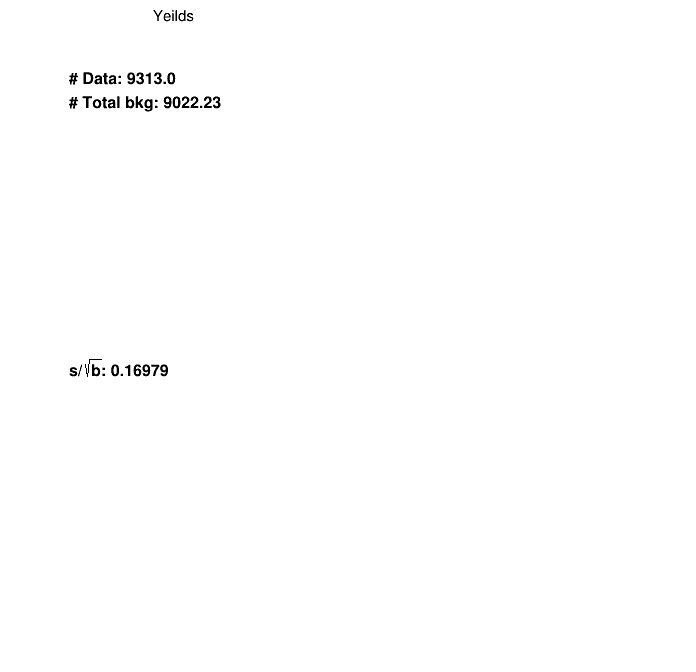

In [21]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

In [22]:
dic_df_raw["TT"]["trigSF_pre"]

0         0.987004
1         0.996223
5         0.993395
12        0.996599
29        0.996223
            ...   
113148    0.999469
113213    0.996223
113215    0.995576
113220    0.991751
113238    0.992456
Name: trigSF_pre, Length: 282661, dtype: float32

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 582
DY1500To2000 : 590
DY2000To3000 : 646
DY500To700 : 537
DY700To800 : 454
DY800To1000 : 533
Zp-1700_CH-345 : 1543
Zp-1700_CH-595 : 1149
Zp-1700_CH-845 : 879
Zp-2100_CH-345 : 1362
Zp-2100_CH-595 : 1142
Zp-2100_CH-845 : 931
Zp-2500_CH-345 : 1275
Zp-2500_CH-595 : 1054
Zp-2500_CH-845 : 835
Zp-2900_CH-1095 : 599
Zp-2900_CH-1345 : 569
Zp-2900_CH-345 : 1186
Zp-2900_CH-595 : 934
Zp-2900_CH-845 : 748
Zp-3300_CH-1095 : 632
Zp-3300_CH-1345 : 486
Zp-3300_CH-1595 : 407
Zp-3300_CH-345 : 1141
Zp-3300_CH-595 : 924
Zp-3700_CH-1095 : 554
Zp-3700_CH-1345 : 461
Zp-3700_CH-1595 : 385
Zp-3700_CH-1845 : 345
Zp-3700_CH-345 : 1019
Zp-3700_CH-595 : 855
Zp-3700_CH-845 : 667
Zp-4100_CH-1095 : 489
Zp-4100_CH-1345 : 415
Zp-4100_CH-1595 : 386
Zp-4100_CH-1845 : 343
Zp-4100_CH-345 : 913
Zp-4100_CH-595 : 767
Zp-4100_CH-845 : 703
TT : 148072
TTSem

       1.34707427e-02, 1.76316599e-01])}
here {'puweightUp': array([2.05281875e+02, 6.36435640e+01, 7.62364610e+02, 4.14619883e-01,
       2.01756954e+01, 1.55685124e+00, 5.63407279e-02, 2.03950515e-01,
       3.02842220e+00, 8.09908238e+00, 0.00000000e+00, 6.53281306e-03,
       0.00000000e+00, 2.21395779e-02, 9.98222262e-03, 7.13417521e-04,
       4.43584453e-03, 1.18996990e-05, 5.15464907e-03, 1.20040186e-03,
       2.96068988e-04, 2.02556752e-04, 2.02158947e-03, 2.18850228e-03,
       1.11175144e-03, 0.00000000e+00, 8.57686628e-04, 3.19999458e-06,
       9.37521729e-04, 2.68272948e-03]), 'puweightDown': array([9.08534272e+01, 1.20437633e+02, 2.71476934e+02, 4.83921989e+00,
       4.61531728e+00, 0.00000000e+00, 1.15406096e-01, 1.31271100e-01,
       2.12390830e+01, 2.79291889e+00, 6.32086454e-01, 4.66217558e-03,
       3.83312630e-02, 9.66638448e-03, 6.10787220e-04, 8.84280128e-04,
       2.14826735e-03, 2.10619245e-05, 3.75779670e-03, 1.27496196e-03,
       1.47812802e-03, 4.86569

       1.94776408e+00, 6.34465396e-02, 1.23279467e-01])}
here {'puweightUp': array([4.55610508e+02, 3.21346893e+02, 5.36362286e+01, 1.71351005e+01,
       1.06010759e+01, 1.68333605e+00, 3.54824937e+00, 4.21138793e-01,
       1.08213043e+00, 3.44269420e-02, 9.78634078e-02, 6.12792943e-01,
       7.89648736e-02, 3.68353615e-01, 2.44317501e-01, 1.61104948e-02,
       0.00000000e+00, 9.29888734e-05, 1.58745700e-02, 3.67506534e-02,
       2.62989184e-02, 1.61826420e-03, 2.86274399e-03, 1.05359641e-03,
       7.51490588e-05, 1.40485805e-04, 3.54747138e-02, 4.32316746e-04,
       1.62731557e-04, 2.37159406e-04, 7.60138865e-04]), 'puweightDown': array([7.19260512e+01, 1.93160099e+02, 5.64354746e+01, 3.03799699e+01,
       7.23966775e+00, 3.42659757e+00, 1.03249563e+01, 2.11046873e-01,
       2.04007648e+00, 4.53413961e-01, 4.19365208e-01, 6.22839744e-01,
       2.01832573e-02, 6.96343056e-01, 1.11114964e-01, 2.23996312e-03,
       1.08056286e-01, 0.00000000e+00, 1.63302323e-01, 5.38435240e-02

        0.        , 67.90617804, 45.65066085, 67.2405108 , 51.59771972])}
here {'puweightUp': array([   0.        ,    0.        ,    0.        ,    0.        ,
          0.        ,    0.        ,    0.        ,    0.        ,
          0.        ,    0.        ,    0.        ,    0.        ,
          0.        ,    0.        ,    0.        ,    0.        ,
       1411.51457726,   63.65642057,   73.2379996 ,    0.        ]), 'puweightDown': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       593.39872227,  36.05577618,  34.93202071,  22.68850915]), 'l1prefiringUp': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.     

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_pre.pdf has

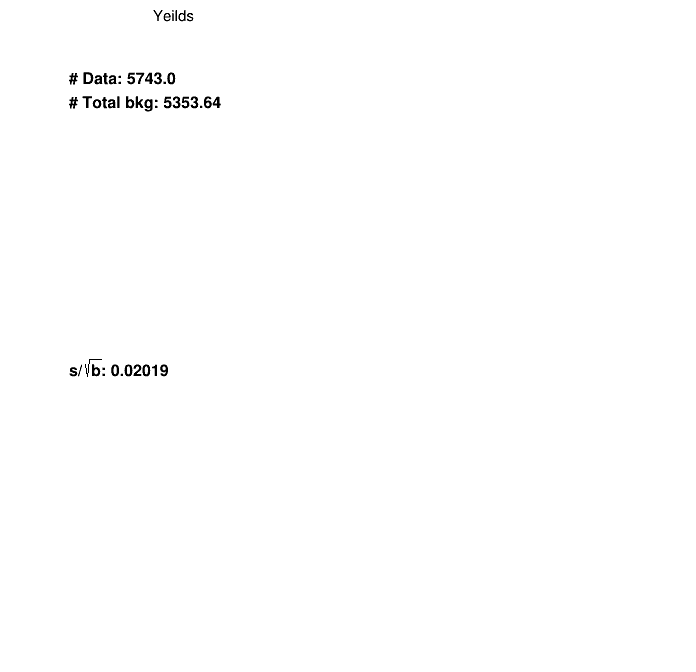

In [23]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [24]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [25]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 0
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 20
Zp-1700_CH-595 : 455
Zp-1700_CH-845 : 1264
Zp-2100_CH-345 : 13
Zp-2100_CH-595 : 213
Zp-2100_CH-845 : 613
Zp-2500_CH-345 : 6
Zp-2500_CH-595 : 74
Zp-2500_CH-845 : 361
Zp-2900_CH-1095 : 360
Zp-2900_CH-1345 : 509
Zp-2900_CH-345 : 4
Zp-2900_CH-595 : 40
Zp-2900_CH-845 : 210
Zp-3300_CH-1095 : 276
Zp-3300_CH-1345 : 298
Zp-3300_CH-1595 : 420
Zp-3300_CH-345 : 6
Zp-3300_CH-595 : 24
Zp-3700_CH-1095 : 176
Zp-3700_CH-1345 : 244
Zp-3700_CH-1595 : 339
Zp-3700_CH-1845 : 340
Zp-3700_CH-345 : 8
Zp-3700_CH-595 : 18
Zp-3700_CH-845 : 82
Zp-4100_CH-1095 : 129
Zp-4100_CH-1345 : 211
Zp-4100_CH-1595 : 231
Zp-4100_CH-1845 : 241
Zp-4100_CH-345 : 2
Zp-4100_CH-595 : 8
Zp-4100_CH-845 : 73
TT : 58917
TTSemi : 164
TTZ : 46699
DY : 1701
top : 87
an

       1.37015052e-01, 3.41521684e-02, 5.11979819e-02, 1.03846056e-01])}
here {'puweightUp': array([1.74513153e+02, 1.48831266e+01, 6.71421486e-01, 2.18471474e+00,
       0.00000000e+00, 2.81286114e+00, 1.04567044e+00, 7.56001745e-02,
       3.87412972e-01, 7.21941297e-02, 3.44115451e-02, 6.06617516e-02,
       8.04750732e-03, 3.68464522e-03, 2.57200149e-03, 4.94168361e-03,
       2.24656409e-04, 1.00499892e-02, 2.13965056e-03, 1.24205342e-02,
       9.25392396e-03, 1.31594185e-04, 4.66045160e-04, 1.05284087e-03,
       8.91765115e-05, 8.84641530e-04, 2.82808993e-04, 2.24945753e-03]), 'puweightDown': array([9.33224497e+02, 5.28670827e+00, 2.27728571e+01, 9.44674145e+00,
       9.65458995e-01, 4.41485614e+00, 5.52795229e-01, 2.28854599e-01,
       1.12241202e-01, 4.16712543e-02, 1.59582306e-02, 1.39472976e-01,
       7.57170366e-02, 2.89556684e-02, 2.16219066e-03, 3.15560135e-03,
       8.90067305e-04, 2.20740197e-02, 3.05603568e-03, 1.48905310e-02,
       6.97250095e-03, 0.00000000e+00

       3.03994708e-01, 1.91499323e+00, 2.03846820e+00])}
here {'puweightUp': array([1.58597814e+02, 1.82984121e+02, 0.00000000e+00, 3.31703657e+01,
       3.16249940e-01, 2.19997366e+00, 5.61718566e+01, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 1.46961382e-01, 1.48370308e+00,
       1.78076705e-01, 6.58708569e-02, 4.47492549e-01, 2.68003854e-01,
       5.78951038e+00, 7.16043421e-01, 3.51347015e-02, 3.40395872e-01,
       1.72424444e-01, 1.52074944e-02, 1.98064497e-01, 2.13402265e-01,
       5.31319820e-04, 1.20103789e-01, 9.83468257e-04, 2.62561127e-02,
       9.26626198e-02, 2.56766652e-04, 1.59610704e-05]), 'puweightDown': array([3.47472379e+02, 1.22527926e+02, 2.61442825e+01, 9.15400352e+01,
       1.77438415e+01, 2.17340903e+00, 2.23262960e+01, 7.93964006e+00,
       3.64386981e+00, 2.61854300e+00, 0.00000000e+00, 4.36918780e+00,
       8.31851864e-02, 7.41414616e-01, 4.61683593e-02, 7.04795197e-01,
       5.12101530e+00, 1.26998471e+00, 1.53464955e-01, 1.39670428e-01

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([1.13835161e+02, 1.93434602e+02, 0.00000000e+00, 0.00000000e+00,
       4.86614886e-02, 1.30235013e+01, 2.31661653e+00, 2.82900538e+00,
       8.39831486e-01, 4.28392208e-02, 8.43010171e-01, 2.32233028e-01,
       4.23528584e-03, 8.39138614e-02, 1.21396536e-02, 1.02947610e-04,
       1.99828071e-04, 6.87959799e-06, 0.00000000e+00, 0.00000000e+00,
       6.36444992e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       5.38601101e-06, 3.76152873e-05, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([2.35266088e+02, 2.34736103e+02, 5.00267480e+01, 1.53208678e+00,
       5.69318930e-01, 3.77713793e+01, 1.37323965e+01, 1.03402404e+01,
       5.34344749e-01, 2.62631999e-01, 8.18538488e-01, 1.24503450e-01,
       7.90891076e-05, 1.74158563e-02, 1.66825383e-02, 2.00007757e-04,
       3.92488987e-05, 6.92373559e-06, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdow

In [26]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 57
DY1500To2000 : 56
DY2000To3000 : 39
DY500To700 : 73
DY700To800 : 66
DY800To1000 : 59
Zp-1700_CH-345 : 1269
Zp-1700_CH-595 : 1125
Zp-1700_CH-845 : 949
Zp-2100_CH-345 : 1268
Zp-2100_CH-595 : 1130
Zp-2100_CH-845 : 891
Zp-2500_CH-345 : 1161
Zp-2500_CH-595 : 1088
Zp-2500_CH-845 : 926
Zp-2900_CH-1095 : 718
Zp-2900_CH-1345 : 620
Zp-2900_CH-345 : 1123
Zp-2900_CH-595 : 1053
Zp-2900_CH-845 : 865
Zp-3300_CH-1095 : 702
Zp-3300_CH-1345 : 545
Zp-3300_CH-1595 : 504
Zp-3300_CH-345 : 937
Zp-3300_CH-595 : 1014
Zp-3700_CH-1095 : 673
Zp-3700_CH-1345 : 522
Zp-3700_CH-1595 : 443
Zp-3700_CH-1845 : 385
Zp-3700_CH-345 : 931
Zp-3700_CH-595 : 864
Zp-3700_CH-845 : 793
Zp-4100_CH-1095 : 618
Zp-4100_CH-1345 : 486
Zp-4100_CH-1595 : 409
Zp-4100_CH-1845 : 352
Zp-4100_CH-345 : 835
Zp-4100_CH-595 : 788
Zp-4100_CH-845 : 731
TT : 90704
TTSemi : 199

       2.73321177e-03, 0.00000000e+00])}{'puweightUp': array([2.60440492e+01, 0.00000000e+00, 1.48236972e-02, 7.48935569e-02,
       1.53439730e-01, 7.46030125e-02, 4.06074094e-02, 2.55941074e-02,
       4.43292926e-02, 2.66382900e-03, 2.60116125e-04, 9.03605689e-03,
       2.79327234e-06, 3.88491868e-03]), 'puweightDown': array([1.94564042e+01, 6.69977388e-01, 3.20010627e-02, 3.02674387e-01,
       9.48278552e-02, 4.92005608e-03, 5.35999453e-02, 1.69848157e-02,
       2.31097006e-02, 3.17089092e-03, 3.13270687e-04, 1.10047727e-03,
       4.08923524e-06, 1.64640101e-02]), 'l1prefiringUp': array([2.53978006e+01, 7.86080210e+00, 1.46101725e+00, 3.14206784e-01,
       8.16449501e-02, 4.11995309e-02, 3.73314289e-03, 1.23717940e-03,
       4.91876926e-04, 8.33987102e-05, 7.86095143e-05, 1.45474579e-05,
       3.02265266e-07, 1.06209791e-05]), 'l1prefiringDown': array([2.53339997e+01, 7.71658823e+00, 1.43867914e+00, 3.04292448e-01,
       8.03340348e-02, 4.05906795e-02, 3.75219080e-03, 1.184

       2.73321177e-03, 0.00000000e+00])}
{'puweightUp': array([2.35445147e-02, 2.19883373e-01, 2.23616182e+01, 2.28566306e-01,
       1.80796120e-03, 0.00000000e+00, 0.00000000e+00, 1.30534522e-02,
       2.78129290e-02, 1.53423353e-01, 3.37456468e-03, 0.00000000e+00,
       7.85944580e-01, 3.01194189e-01, 1.65074140e+00, 2.80155084e+00,
       0.00000000e+00]), 'puweightDown': array([1.93781666e-01, 1.94934829e-03, 1.01224414e+01, 1.10045224e+00,
       2.55272837e-01, 2.23177853e-01, 8.39554498e-03, 3.66285233e-03,
       4.47034646e-01, 3.75061523e-02, 8.29695728e-02, 8.32510856e-01,
       0.00000000e+00, 8.88701730e-01, 4.67020646e+00, 4.03225199e+00,
       0.00000000e+00]), 'l1prefiringUp': array([2.52046011, 2.93564219, 2.73367292, 1.78884853, 1.45280912,
       1.31656073, 1.19382915, 0.80367543, 1.08680377, 0.88718309,
       1.46305875, 2.7551932 , 3.11550906, 4.78193095, 4.65667863,
       3.88556207, 0.        ]), 'l1prefiringDown': array([2.48317954, 2.89161825, 2.7107745

        0.06438396,  0.05349419,  0.05043349,  0.47164591,  0.06111061])}{'puweightUp': array([1.76993066e-01, 5.98315473e+00, 0.00000000e+00, 4.81322332e+00,
       1.57395399e-02, 1.79783302e-02, 4.04502872e-01, 3.09039033e-03,
       3.46755311e-03, 7.06339851e-01, 4.05246201e+00, 2.95476586e-03,
       1.29661785e-01, 3.55765415e-01, 8.43211511e-01, 2.19711474e+00,
       0.00000000e+00]), 'puweightDown': array([0.        , 3.32813887, 0.29200036, 3.0248202 , 0.53415514,
       0.33254174, 0.27339087, 0.18462023, 0.00527086, 1.47717061,
       2.28568371, 0.01073394, 1.01570478, 1.20891482, 2.99813136,
       1.75002496, 0.        ]), 'l1prefiringUp': array([2.61864529, 3.15398041, 2.30953617, 2.5611993 , 1.65117111,
       1.03097596, 0.95469241, 0.95535679, 0.56775633, 0.88699685,
       1.64142752, 2.26044169, 2.9045388 , 4.02229176, 7.4440024 ,
       3.53892169, 0.        ]), 'l1prefiringDown': array([2.59265985, 3.10510061, 2.28814954, 2.53342406, 1.63141255,
       1.0165087

        8.62349761,  0.        ])}{'puweightUp': array([1.96138596e+00, 1.03219237e+01, 8.06516871e+00, 2.86214407e-01,
       1.62252289e+00, 2.38012910e-01, 1.07620655e-02, 1.12308141e-02,
       5.19511022e-05, 4.43925272e-04, 0.00000000e+00, 1.00242720e-04,
       1.31557721e-05, 1.17886873e-08, 0.00000000e+00, 2.70646205e-10,
       1.57282091e-09]), 'puweightDown': array([5.83128286e-01, 1.62774234e+01, 1.81520020e+01, 2.51572301e+00,
       1.66372000e+00, 5.09207237e-03, 3.58632659e-03, 1.25158735e-02,
       7.64308740e-04, 1.05470813e-03, 1.03033246e-04, 2.89855042e-04,
       3.77545964e-06, 1.77145299e-08, 1.45558319e-10, 1.27840458e-09,
       1.91668432e-09]), 'l1prefiringUp': array([9.78601201e+01, 1.60650077e+01, 1.88825478e+01, 1.44603201e+01,
       1.36074885e+00, 9.54307415e-02, 1.16150050e-05, 6.61451247e-04,
       4.22221983e-05, 6.49587998e-06, 1.45919724e-06, 3.38026548e-06,
       1.02319618e-05, 8.40785627e-11, 0.00000000e+00, 1.36627183e-12,
       0.0000000

        8.62349761,  0.        ])}

{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 1.30093123e+00, 5.77039954e+00,
       1.86521036e-01, 2.58291018e-01, 1.00990255e-01, 2.64570697e-03,
       1.40212383e-04, 8.90695108e-03, 2.10414825e-03, 5.88536140e-03,
       4.58363654e-04, 1.75615995e-02]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 7.51899140e+00, 6.70290188e+00,
       4.78506472e-01, 5.73810599e-01, 9.59590828e-03, 4.08243225e-02,
       6.66806793e-03, 8.96478302e-03, 4.43360070e-03, 1.46029926e-03,
       0.00000000e+00, 2.28123662e-02]), 'l1prefiringUp': array([0.00000000e+00, 0.00000000e+00, 1.92293833e+02, 3.52139700e+01,
       4.79555219e+00, 7.62418227e-01, 1.43732514e-01, 3.34568617e-02,
       4.27908139e-03, 6.33459524e-04, 3.74766646e-04, 2.79209580e-04,
       8.49700937e-05, 4.09337177e-05]), 'l1prefiringDown': array([0.00000000e+00, 0.00000000e+00, 1.93401025e+02, 3.50716491e+01,
       4.71832847e+00, 7.60986841e-01, 1.42066358e-01, 3.3172871

       3.73147841e-01, 2.80129461e-01, 9.28732454e-01])}
here {'puweightUp': array([5.33143983e-09, 3.87032507e-04, 1.23591894e+00, 1.96519661e-01,
       7.78610424e+00, 3.19941886e-01, 1.88847391e+00, 5.06880275e-01,
       3.11314306e+00, 6.56768265e-02, 7.89761450e-01, 3.61041928e+00,
       1.37166783e+00, 0.00000000e+00, 6.08618054e-01, 2.60084562e+00,
       3.10520150e-02, 1.01429967e+00, 1.06029968e-02, 0.00000000e+00,
       6.10100681e-01, 1.05375733e+00, 5.21798250e-02, 9.67834441e-04,
       1.48352710e-02, 6.98210466e-04, 0.00000000e+00]), 'puweightDown': array([3.54936114e-07, 2.79224651e-03, 1.21343350e+00, 3.83133797e-01,
       8.40270595e+00, 7.47679440e-02, 4.47024329e-01, 1.70450163e+00,
       5.65360761e+00, 4.41116191e-01, 1.49412719e+00, 2.93243535e+00,
       2.89873907e+00, 1.89430251e-01, 9.90774064e-01, 1.32575371e+00,
       2.59145760e-02, 6.54251843e-01, 1.25364991e-01, 4.93342550e-02,
       6.26828267e-01, 8.38017330e-01, 3.26489561e-02, 4.36716515e-03

        0.45738264,  0.26527077,  0.48874227,  0.31660142])}
here {'puweightUp': array([8.12178467e+00, 5.80287385e-01, 6.25076399e-01, 4.79634023e+00,
       9.78898483e-02, 9.71970120e-04, 5.74084934e+00, 5.07123037e-02,
       3.27756504e-01, 8.29633414e-02, 9.38961942e-02, 1.27585794e-01,
       2.31994664e-01, 2.67983928e-02]), 'puweightDown': array([1.86100074e+01, 8.46091317e-01, 9.97659052e-01, 3.90255519e+00,
       2.31672694e+00, 7.05658834e-03, 3.70149754e+00, 2.98050610e-01,
       3.81538179e-01, 3.80240571e-02, 3.46459724e-02, 3.64264807e-03,
       2.33706538e-01, 2.89136100e-02]), 'l1prefiringUp': array([4.35577093e+00, 2.24489787e+01, 1.55231709e+01, 1.48390371e+01,
       1.20792066e+01, 6.14257766e+00, 1.48272183e+00, 4.33833129e-01,
       3.58807432e-01, 4.12545098e-02, 2.37883073e-02, 8.16894149e-03,
       1.34132616e-03, 1.41971825e-03]), 'l1prefiringDown': array([4.43347913e+00, 2.28017702e+01, 1.56372444e+01, 1.48356750e+01,
       1.19729018e+01, 6.00553065e

       0.00000000e+00, 0.00000000e+00])}
{'puweightUp': array([6.46817465e+00, 2.74146053e+00, 2.47185519e-01, 1.56959040e+00,
       1.66775617e+00, 2.57078573e-01, 0.00000000e+00, 8.48965570e-02,
       8.00170951e-03, 1.26300507e-01, 6.95763874e-04, 0.00000000e+00,
       5.04921128e-04, 3.06395213e-05, 6.14489692e-03]), 'puweightDown': array([2.20100924e+01, 2.65153026e+00, 0.00000000e+00, 5.84507681e+00,
       5.50151165e-01, 3.23749871e-01, 2.19710753e-02, 5.61528450e-03,
       1.40312268e-02, 1.88329356e-01, 8.22128402e-04, 1.79517230e-05,
       1.47070429e-04, 5.51163992e-05, 2.26435337e-04]), 'l1prefiringUp': array([1.77674054e+02, 3.46432336e+01, 6.87508366e+00, 8.07213162e-01,
       9.47491283e-02, 1.28960450e-01, 5.97372429e-03, 1.70986016e-03,
       1.35039882e-04, 2.68174615e-04, 4.12835274e-05, 2.14034922e-05,
       7.51810639e-06, 4.57838300e-07, 2.18003226e-05]), 'l1prefiringDown': array([1.78009783e+02, 3.44796516e+01, 6.90598566e+00, 8.04868489e-01,
       9.42

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230424_17/Presel/ee17/PTSB/norm_mass_pre>100 and pt_l

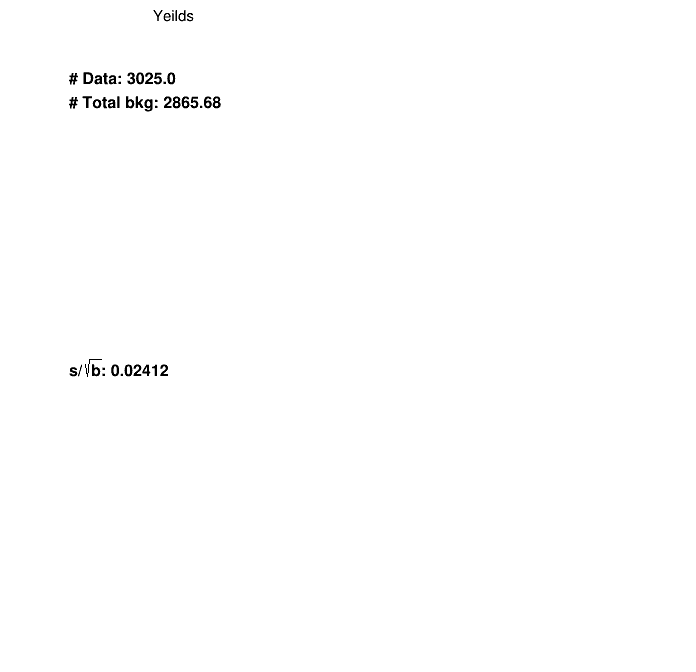

In [27]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [28]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [29]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [30]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file sigeff_ee17.pdf has been created


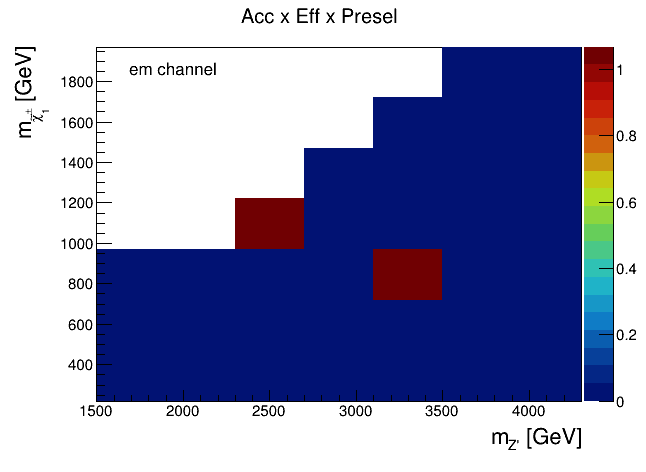

In [31]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")